<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/_banners/opim5512_banner.svg" alt="OPIM 5512 banner" width="100%">

# Lab 5 Bonus · Lags, tsfresh, an Ensemble, and a Forecast Range
### Not one number per hour: a low, an expected and a high load for every hour

*Optional · about 60 minutes · Colab · the same Bradley weather and Connecticut load as Lab 5*

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drdave-teaching/OPIM5512-notebooks/blob/main/Module4/Lab5_Bonus_Features_Ensembles_Ranges.ipynb)

In Lab 5 your model makes **one number** per hour from 11 features. This notebook tries four upgrades, each one an
idea for the final project:

| Part | Time | What you do |
|---|---|---|
| **0. Setup** | 3 min | Same data and split as Lab 5 |
| **1. The window method** | 15 min | Lags of load and temperature, added **one group at a time**, and the 24-hour rule that decides which lags production can use |
| **2. tsfresh** | 10 min | Let a library compute ~700 summary features of last week's load, keep the relevant ones, and see if they help |
| **3. Three models, one ensemble** | 8 min | Gradient boosting, random forest, extra trees, and their average |
| **4. Low, expected, high: four ways** | 15 min | Random forest spread vs quantile forest vs quantile boosting vs linear quantile regression, judged by the leaderboard's own score |
| **5. Tomorrow's range** | 5 min | The range for the next 24 hours from your own bucket |
| **6. Wrap up** | 4 min | Short answers and final-project ideas |

**Nothing here touches production.** `forecast-24h` keeps running the model you shipped in Lab 5. Part 6 lists what it
would take to ship these ideas.

# Part 0 · Setup (3 min)
The same scikit-learn as production, plus `quantile-forest` (Part 4) and `tsfresh` (Part 2). If Colab asks you to
restart the session, click it, then run the notebook again from the top.

In [1]:
!pip install -q scikit-learn==1.6.1 quantile-forest==1.4.2 tsfresh==0.21.2

import io
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)
SEED = 42
DATA = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/"
df = pd.read_csv(DATA + "bdl_ct_load_hourly_2023_2026.csv", index_col="hour_utc", parse_dates=["hour_utc"])
print(len(df), "hours, from", df["hour_local"].iloc[0], "to", df["hour_local"].iloc[-1])

scikit-learn 1.6.1 | pandas 2.2.3


33215 hours, from 2023-01-01 00:00 EST to 2026-10-15 23:00 EDT


Lab 5's `make_features`, word for word (the 11 features production builds), the `score` helper, and the same gradient
boosting settings as Lab 5 (with early stopping).

In [2]:
WEATHER = ["temp_f", "dewpoint_f", "rel_humidity_pct", "wind_speed_mph", "cloud_cover_pct"]
CALENDAR = ["hour", "day_of_week", "month", "is_weekend", "is_holiday"]
FEATURES = CALENDAR + WEATHER + ["load_yesterday_mw"]


def make_features(hours_utc, weather, load):
    """Lab 5's 11 features: one row of model inputs per hour."""
    hours_utc = pd.DatetimeIndex(hours_utc)
    local = hours_utc.tz_convert("America/New_York")
    out = pd.DataFrame(index=hours_utc)
    out["hour"] = local.hour
    out["day_of_week"] = local.dayofweek
    out["month"] = local.month
    out["is_weekend"] = (local.dayofweek >= 5).astype(int)
    holidays = USFederalHolidayCalendar().holidays(start="2020-01-01", end="2030-12-31")
    out["is_holiday"] = local.tz_localize(None).normalize().isin(holidays).astype(int)
    for column in WEATHER:
        out[column] = weather[column].reindex(hours_utc).values
    yesterday = load.reindex(hours_utc - pd.Timedelta(hours=24)).values
    hour_before = load.reindex(hours_utc - pd.Timedelta(hours=25)).values
    out["load_yesterday_mw"] = np.where(np.isnan(yesterday), hour_before, yesterday)
    return out[FEATURES]


def score(name, actual, predicted):
    return {"model": name,
            "test_mae_mw": round(mean_absolute_error(actual, predicted), 1),
            "test_mape_pct": round(100 * mean_absolute_percentage_error(actual, predicted), 2)}


def booster():
    """Lab 5's gradient boosting with early stopping: it stops adding trees once 20 in a row fail to help."""
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=1000, max_leaf_nodes=31, early_stopping=True,
                                         validation_fraction=0.1, n_iter_no_change=20,
                                         scoring="neg_mean_absolute_error", tol=0.5, random_state=SEED)

# Part 1 · The window method (15 min)
The **window method** turns the past into features: the load 24 hours ago, 48 hours ago, a week ago, yesterday's
average, the temperature 3 hours ago. Electricity use repeats (today looks like yesterday, this Tuesday looks like last
Tuesday), so the recent past is a strong clue. Lab 5's model has exactly **one** lag: `load_yesterday_mw`.

### 1a. The 24-hour rule: which lags can production use?
`forecast-24h` runs at 2:20 p.m. and forecasts **3 p.m. today to 2 p.m. tomorrow** with **one** model. The newest load
it knows is the 1 p.m. hour. A lag is only usable if it is known for **every** hour the model forecasts. Check:

In [3]:
issued = pd.Timestamp("2026-10-14 14:20", tz="America/New_York")
newest_over = issued.floor("h") - pd.Timedelta(hours=1)          # 1 p.m.: the newest hour that is over
rows = []
for lead in [1, 6, 12, 23, 24]:
    target = issued.floor("h") + pd.Timedelta(hours=lead)
    row = {"hours ahead": lead, "forecast hour": target.strftime("%a %I %p")}
    for back in [1, 24, 48, 168]:
        source = target - pd.Timedelta(hours=back)
        if source <= newest_over:
            row["load " + str(back) + " h before"] = "known"
        else:
            row["load " + str(back) + " h before"] = "NOT YET"
    rows.append(row)
pd.DataFrame(rows)

,hours ahead,forecast hour,load 1 h before,load 24 h before,load 48 h before,load 168 h before
0,1,Wed 03 PM,NOT YET,known,known,known
1,6,Wed 08 PM,NOT YET,known,known,known
2,12,Thu 02 AM,NOT YET,known,known,known
3,23,Thu 01 PM,NOT YET,known,known,known
4,24,Thu 02 PM,NOT YET,NOT YET,known,known


**Read it:** the load 1 hour before is only known for the very next hour, so a single 24-hour model can't use it.
The load 24 hours before is known for every hour except the last one (that's why Lab 5 falls back to 25 hours
there). 48 hours and a week back are always known. **Weather lags are different:** the forecast covers yesterday and
tomorrow, so the temperature 3 hours earlier is always available.

*(Final-project idea: 24 separate models, one per hour ahead, can each use the freshest lag allowed for their own lead.
That's called the **direct** strategy.)*

### 1b. Build the lags
Twelve new features, all buildable at forecast time:

| New feature | Group | Idea |
|---|---|---|
| `load_2_days_ago_mw`, `load_last_week_mw` | load lags | the same hour 48 and 168 hours earlier |
| `load_yesterday_avg_mw`, `load_yesterday_peak_mw` | load windows | how big yesterday was overall, not just at this hour |
| `temp_3h_ago_f`, `temp_avg_24h_f` | temperature history | buildings heat up and cool down slowly; a hot day after a hot night is worse |
| `heating_degrees`, `cooling_degrees`, `day_of_year` | shape and season | `max(65 − temp, 0)` and `max(temp − 65, 0)`: the two arms of the U-shape |
| `wind_gust_mph`, `wind_dir_deg`, `precip_in` | more weather | the rest of the airport report |

In [4]:
EXTRA_WEATHER = ["wind_gust_mph", "wind_dir_deg", "precip_in"]


def make_features_plus(hours_utc, weather, load):
    """Lab 5's 11 features plus 12 more, every one buildable at forecast time."""
    out = make_features(hours_utc, weather, load)
    hours_utc = pd.DatetimeIndex(hours_utc)
    local = hours_utc.tz_convert("America/New_York")
    for column in EXTRA_WEATHER:
        out[column] = weather[column].reindex(hours_utc).values
    out["day_of_year"] = local.dayofyear
    out["heating_degrees"] = np.maximum(65 - out["temp_f"], 0)
    out["cooling_degrees"] = np.maximum(out["temp_f"] - 65, 0)
    out["temp_3h_ago_f"] = weather["temp_f"].reindex(hours_utc - pd.Timedelta(hours=3)).values
    out["temp_avg_24h_f"] = weather["temp_f"].rolling(24).mean().reindex(hours_utc).values
    out["load_2_days_ago_mw"] = load.reindex(hours_utc - pd.Timedelta(hours=48)).values
    out["load_last_week_mw"] = load.reindex(hours_utc - pd.Timedelta(hours=168)).values
    # yesterday = the 24 hours that ended 24 hours before this hour
    out["load_yesterday_avg_mw"] = load.rolling(24).mean().reindex(hours_utc - pd.Timedelta(hours=24)).values
    out["load_yesterday_peak_mw"] = load.rolling(24).max().reindex(hours_utc - pd.Timedelta(hours=24)).values
    return out


X_plus = make_features_plus(df.index, df, df["load_mw"]).dropna()    # the first week has no "last week": dropped
y_plus = df["load_mw"].reindex(X_plus.index)
PLUS = list(X_plus.columns)

years = X_plus.index.tz_convert("America/New_York").year
TEST_YEAR = years.max()
X_train = X_plus[years < TEST_YEAR]
X_test = X_plus[years == TEST_YEAR]
y_train = y_plus[years < TEST_YEAR]
y_test = y_plus[years == TEST_YEAR]
print(len(PLUS), "features |", len(X_train), "training hours |", len(X_test), "test hours (" + str(TEST_YEAR) + ")")

23 features | 26136 training hours | 6911 test hours (2026)


### 1c. Add one group at a time
Same model, same hours, same split; only the feature list grows. Each bar is the 2026 test-year MAE after adding one
more group. (About 2 minutes.)

Lab 5's 11 features -> 120.7 MW


+ load 2 days and 1 week ago -> 118.0 MW


+ yesterday's average and peak -> 117.1 MW


+ temperature history -> 108.4 MW


+ heating/cooling degrees, day of year -> 108.3 MW


+ the rest of the weather -> 107.3 MW


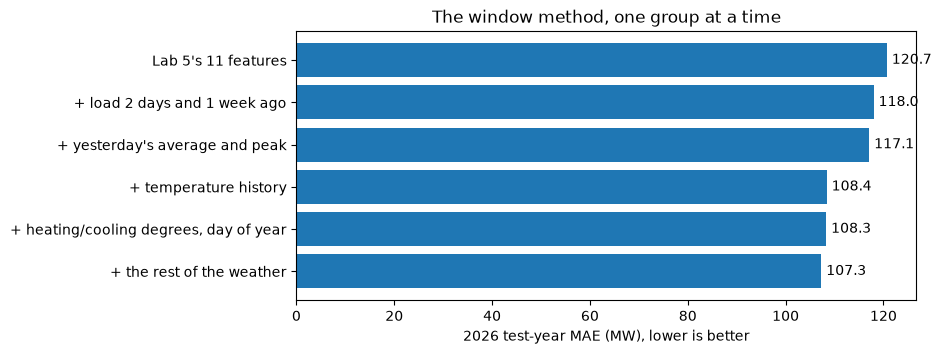

,step,features,test_mae_mw,trees
0,Lab 5's 11 features,11,120.7,358
1,+ load 2 days and 1 week ago,13,118.0,409
2,+ yesterday's average and peak,15,117.1,498
3,+ temperature history,17,108.4,545
4,"+ heating/cooling degrees, day of year",20,108.3,565
5,+ the rest of the weather,23,107.3,580


In [5]:
GROUPS = [("Lab 5's 11 features", FEATURES),
          ("+ load 2 days and 1 week ago", ["load_2_days_ago_mw", "load_last_week_mw"]),
          ("+ yesterday's average and peak", ["load_yesterday_avg_mw", "load_yesterday_peak_mw"]),
          ("+ temperature history", ["temp_3h_ago_f", "temp_avg_24h_f"]),
          ("+ heating/cooling degrees, day of year", ["heating_degrees", "cooling_degrees", "day_of_year"]),
          ("+ the rest of the weather", EXTRA_WEATHER)]

used = []
steps = []
for label, columns in GROUPS:
    used = used + columns
    model = booster().fit(X_train[used], y_train)
    mae = mean_absolute_error(y_test, model.predict(X_test[used]))
    steps.append({"step": label, "features": len(used), "test_mae_mw": round(mae, 1), "trees": model.n_iter_})
    print(label, "->", round(mae, 1), "MW")
steps = pd.DataFrame(steps)

plt.figure(figsize=(8, 3.5))
plt.barh(steps["step"], steps["test_mae_mw"])
plt.gca().invert_yaxis()
for i in range(len(steps)):
    plt.text(steps["test_mae_mw"].iloc[i] + 1, i, str(steps["test_mae_mw"].iloc[i]), va="center")
plt.xlabel("2026 test-year MAE (MW), lower is better")
plt.title("The window method, one group at a time")
plt.show()
steps

**Read it:** the surprise is **temperature history**: the temperature 3 hours ago and the 24-hour average temperature
save about 9 MW, more than all the extra load lags together (about 4 MW). The model already has yesterday's load at
this hour, so more load history repeats what it knows, while "it has been hot all day" is new information: buildings
store heat. The last two groups add almost nothing. That's typical: later features fight over what's left.

Which features did the work? Permutation importance on the full model, the same way as Lab 5 Part 6c.

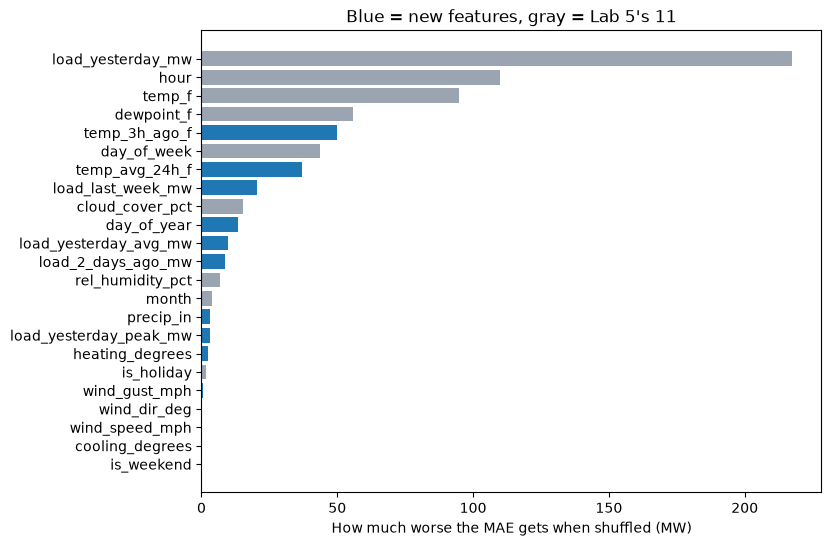

In [6]:
from sklearn.inspection import permutation_importance

boost_plus = booster().fit(X_train[PLUS], y_train)
pred_boost = boost_plus.predict(X_test[PLUS])
perm = permutation_importance(boost_plus, X_test[PLUS], y_test, n_repeats=5, random_state=SEED,
                              scoring="neg_mean_absolute_error", n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=PLUS).sort_values()
colors = []
for name in importance.index:
    if name in FEATURES:
        colors.append("#9aa5b1")
    else:
        colors.append("#1f77b4")
plt.figure(figsize=(8, 6))
plt.barh(importance.index, importance.values, color=colors)
plt.xlabel("How much worse the MAE gets when shuffled (MW)")
plt.title("Blue = new features, gray = Lab 5's 11")
plt.show()

**The production catch for the week-old lag:** your `scraper-isone` only has load since the day you deployed it, so
`load_last_week_mw` stays empty in production for your first week. Before you ship it, either wait a week, or ask
Dr. Dave about a one-time backfill (the scraper accepts `{"five_min_days": 8}` to fetch the last 8 days), and keep a
fallback like Lab 5's for any missing hour.

**Your turn (optional):** add one lag of your own to `make_features_plus` (ideas: the load 72 hours ago, the average
temperature over the last 3 days, `cooling_degrees` × `hour`), re-run 1b and 1c, and see whether the MAE moves.
Check it against the 1a table first: can production know it for every hour?

# Part 2 · tsfresh: let a library invent the window features (10 min)
Part 1 hand-picked a dozen lags. **tsfresh** ("time series feature extraction on the basis of scalable hypothesis
tests") goes the other way: give it a window of a time series and it computes **hundreds** of summary numbers
(averages, quantiles, trends, autocorrelations, peaks, Fourier coefficients, entropy, ...), then tests each one and
keeps only those that are statistically related to the target. It's a maintained open-source library (version 0.21.2,
May 2026).

**The honest window.** One window per day: for every forecast day **D**, the **7 full days that ended at midnight
before D − 1**. Even the 2:20 p.m. forecast made on D − 1 already knows all of it, so production could build these
features too. Every hour of day D gets that day's features.

In [7]:
from tsfresh import extract_features
from tsfresh.feature_extraction import EfficientFCParameters
from tsfresh.feature_selection.relevance import calculate_relevance_table
from tsfresh.utilities.dataframe_functions import impute

# Load on Connecticut time, so a "day" is a Connecticut calendar day
load_local = df["load_mw"].copy()
load_local.index = df.index.tz_convert("America/New_York")
days = pd.DatetimeIndex(sorted(set(load_local.index.normalize())))

# tsfresh wants a LONG table: one row per (window id, time step, value)
pieces = []
for day in days[8:]:                                     # the first 8 days have no full week before them
    window_end = day - pd.DateOffset(days=1)             # midnight that starts day D - 1 (DateOffset = calendar days)
    window = load_local[(load_local.index >= window_end - pd.DateOffset(days=7)) & (load_local.index < window_end)]
    pieces.append(pd.DataFrame({"day": day.strftime("%Y-%m-%d"), "step": np.arange(len(window)),
                                "load": window.values}))
windows = pd.concat(pieces, ignore_index=True)
print(windows["day"].nunique(), "windows of about 168 hours |", len(windows), "rows")
windows.head()

1376 windows of about 168 hours | 231161 rows


,day,step,load
0,2023-01-09,0,2402.708
1,2023-01-09,1,2296.444
2,2023-01-09,2,2206.413
3,2023-01-09,3,2165.396
4,2023-01-09,4,2153.655


Now the extraction. `EfficientFCParameters` skips tsfresh's slowest calculators. (About 1 to 3 minutes.)

In [8]:
started = time.time()
week_features = extract_features(windows, column_id="day", column_sort="step",
                                 default_fc_parameters=EfficientFCParameters(), disable_progressbar=True)
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # impute() warns about every column it fixes
impute(week_features)                                    # a few calculators return NaN or inf: tsfresh's own fix
print(week_features.shape[1], "features for each of", week_features.shape[0], "days, in",
      round(time.time() - started), "seconds")
week_features.iloc[:3, :6]

777 features for each of 1376 days, in 37 seconds


,load__variance_larger_than_standard_deviation,load__has_duplicate_max,load__has_duplicate_min,load__has_duplicate,load__sum_values,load__abs_energy
2023-01-09,1.0,0.0,0.0,0.0,498422.346,1.510580e+09
2023-01-10,1.0,0.0,0.0,0.0,509612.701,1.573871e+09
2023-01-11,1.0,0.0,0.0,0.0,516185.928,1.614204e+09


**How to read a name:** `column__calculator__settings`. So `load__quantile__q_0.9` is the 90th percentile of last
week's load, `load__mean` is its average, and `load__fft_coefficient__attr_"abs"__coeff_7` is the strength of a
7-cycles-per-week wave.

**Keep the relevant ones.** tsfresh tests each feature against a target, here **day D's average load**, using
**training days only** (testing on 2026 would be peeking).

In [9]:
daily_avg = load_local.groupby(load_local.index.normalize()).mean()
daily_avg.index = daily_avg.index.strftime("%Y-%m-%d")
target = daily_avg.reindex(week_features.index)
train_days = week_features.index < str(TEST_YEAR) + "-01-01"

relevance = calculate_relevance_table(week_features[train_days], target[train_days])
relevance = relevance[relevance["relevant"]].sort_values("p_value")
print(len(relevance), "of", week_features.shape[1], "features pass tsfresh's test")
TOP_N = 10
TSFRESH = list(relevance["feature"].head(TOP_N))
relevance[["p_value"]].head(TOP_N)

482 of 777 features pass tsfresh's test


,p_value
feature,
load__abs_energy,3.329677e-185
load__root_mean_square,4.348572e-185
load__c3__lag_1,7.029991e-185
load__c3__lag_2,2.490879e-184
load__sum_values,3.142689e-184
"load__fft_coefficient__attr_""abs""__coeff_0",3.142689e-184
"load__fft_coefficient__attr_""real""__coeff_0",3.142689e-184
load__mean,4.346729e-184
load__quantile__q_0.7,6.782153e-184


Give every hour its day's tsfresh features, then compare against Part 1 with the same model.

In [10]:
day_of_hour = X_plus.index.tz_convert("America/New_York").strftime("%Y-%m-%d")
X_ts = X_plus.copy()
for name in TSFRESH:
    X_ts[name] = week_features[name].reindex(day_of_hour).values
X_ts = X_ts.dropna()                                     # the first days have no tsfresh window
train_rows = X_ts.index.isin(X_train.index)
test_rows = X_ts.index.isin(X_test.index)
y_ts = y_plus.reindex(X_ts.index)

rows = []
for label, columns in [("Lab 5's 11", FEATURES), ("Lab 5's 11 + tsfresh top " + str(TOP_N), FEATURES + TSFRESH),
                       ("Part 1's " + str(len(PLUS)), PLUS), ("Part 1's " + str(len(PLUS)) + " + tsfresh", PLUS + TSFRESH)]:
    model = booster().fit(X_ts.loc[train_rows, columns], y_ts[train_rows])
    rows.append(score(label, y_ts[test_rows], model.predict(X_ts.loc[test_rows, columns])))
pd.DataFrame(rows)

,model,test_mae_mw,test_mape_pct
0,Lab 5's 11,120.9,3.89
1,Lab 5's 11 + tsfresh top 10,123.1,3.97
2,Part 1's 23,109.0,3.53
3,Part 1's 23 + tsfresh,109.8,3.55


**Read it:** no help, even a hair worse. Look at the top 10: `abs_energy`, `root_mean_square`, `sum_values`, `mean`,
the 70th and 80th percentiles... they are all the same idea, **"how much load was there last week"**, ten times over.
The model already knows that from `load_yesterday_mw` (and Part 1's lags), so ten copies only add noise to split on.
Ranking by p-value picks the **strongest** features, not **different** ones.

tsfresh is a **discovery** tool: when you don't know which summaries of a window matter, it proposes hundreds and
tests them. Here, the hand-made lags already said it.

**Your turn (optional):** pick 10 from **different** calculators instead (one quantile, one trend like
`linear_trend`, one autocorrelation, one FFT coefficient, ...), or run tsfresh on a week of **temperature**, and
re-run the comparison. Part 1 says the temperature history was where the new information was.

**To ship it:** `forecast-24h` would need `tsfresh==0.21.2` in its `requirements.txt`, at least 9 days of load in your
bucket, and this exact window rule. Same features in training and production, every time.

# Part 3 · Three models, one ensemble (8 min)
An **ensemble** averages several models. It helps when the models are about equally good **and** make different
mistakes. Here: gradient boosting (Lab 5's champion), a random forest, and extra trees (a random forest that picks its
split points at random, so it makes different mistakes). All three see the same 23 features.

In [11]:
models = {
    "gradient boosting": booster(),
    "random forest": RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    "extra trees": ExtraTreesRegressor(n_estimators=200, max_depth=20, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
}
preds = {}
rows = []
for name in models:
    started = time.time()
    models[name].fit(X_train[PLUS], y_train)
    preds[name] = models[name].predict(X_test[PLUS])
    rows.append(score(name, y_test, preds[name]))
    print(name, "done in", round(time.time() - started), "seconds")

equal = (preds["gradient boosting"] + preds["random forest"] + preds["extra trees"]) / 3
rows.append(score("ensemble: equal average of the three", y_test, equal))
weighted = 0.6 * preds["gradient boosting"] + 0.2 * preds["random forest"] + 0.2 * preds["extra trees"]
rows.append(score("ensemble: 60% boosting, 20% + 20%", y_test, weighted))
pd.DataFrame(rows).sort_values("test_mae_mw")

gradient boosting done in 2 seconds


random forest done in 13 seconds


extra trees done in 4 seconds


,model,test_mae_mw,test_mape_pct
0,gradient boosting,107.3,3.47
4,"ensemble: 60% boosting, 20% + 20%",112.9,3.67
3,ensemble: equal average of the three,120.3,3.91
2,extra trees,131.0,4.26
1,random forest,139.5,4.51


**Read the table before you celebrate.** If the ensemble loses to boosting alone, the two forests are dragging it down:
averaging a strong model with weaker ones only helps when their errors cancel out. Real forecasters choose the weights
on a **validation** period (never the test year), or tune each member until all of them are strong. Lab 5's rule
still applies: one great model often beats a committee.

# Part 4 · Low, expected, high: four ways (15 min)
For every hour we want three numbers:
- **low** = the 10th percentile: only 1 hour in 10 should come in below it
- **expected** = the 50th percentile (the median)
- **high** = the 90th percentile: only 1 hour in 10 should come in above it

So about **8 in 10** real hours should land between low and high. Four ways to get them:

| Method | How it gets a range |
|---|---|
| **Random forest spread** | 200 trees each make a guess; low and high = the 10th and 90th percentile **of the trees' guesses** |
| **Quantile regression forest** | the same kind of forest, but each leaf keeps **every training load** that landed in it; low and high = percentiles of **those loads** |
| **Quantile gradient boosting** | three boosted models, each trained to hit one percentile (the "pinball" loss punishes misses on the wrong side harder) |
| **Linear quantile regression** | three straight-line models, each fit to one percentile instead of the average |

**The judge** is the leaderboard's own score for a range (lower is better), plus two checks: how often the actual
landed inside (aim: 80%) and how wide the range is.

In [12]:
QUANTILES = [0.1, 0.5, 0.9]


def judge(method, low, expected, high, actual=y_test):
    """The leaderboard's range score, plus coverage and width, averaged over the test hours."""
    actual = np.asarray(actual)
    low = np.asarray(low)
    high = np.asarray(high)
    expected = np.asarray(expected)
    width = high - low
    outside = np.maximum(low - actual, 0) + np.maximum(actual - high, 0)
    score_mw = (0.5 * np.abs(actual - expected) + 0.1 * width + 1 * outside) / 1.5
    return {"method": method,
            "inside_range_pct": round(100 * float(np.mean(outside == 0)), 1),
            "avg_width_mw": round(float(np.mean(width))),
            "expected_mae_mw": round(float(np.mean(np.abs(actual - expected))), 1),
            "range_score": round(float(np.mean(score_mw)), 1)}


ranges = {}          # method -> table of low, expected, high for every test hour
results = []

### 4a. Random forest spread
A plain random forest. Each of its 200 trees predicts every test hour; we read the 10th, 50th and 90th percentile of
those 200 guesses.

In [13]:
started = time.time()
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
forest.fit(X_train[PLUS], y_train)
guesses = []
for tree in forest.estimators_:
    guesses.append(tree.predict(X_test[PLUS].values))      # one row of guesses per tree
guesses = np.array(guesses)
ranges["random forest spread"] = pd.DataFrame({"low": np.percentile(guesses, 10, axis=0),
                                               "expected": np.percentile(guesses, 50, axis=0),
                                               "high": np.percentile(guesses, 90, axis=0)}, index=X_test.index)
results.append(judge("random forest spread", ranges["random forest spread"]["low"],
                     ranges["random forest spread"]["expected"], ranges["random forest spread"]["high"]))
print("done in", round(time.time() - started), "seconds")
pd.DataFrame(results)

done in 11 seconds


,method,inside_range_pct,avg_width_mw,expected_mae_mw,range_score
0,random forest spread,76.6,405,142.5,92.0


### 4b. Quantile regression forest
The same forest settings, read a different way: not the spread of the **trees' averages**, but the spread of the
**actual training loads** that hours like this one had.

In [14]:
from quantile_forest import RandomForestQuantileRegressor

started = time.time()
qrf = RandomForestQuantileRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
qrf.fit(X_train[PLUS], y_train)
q = qrf.predict(X_test[PLUS], quantiles=QUANTILES)          # one column per quantile
ranges["quantile forest"] = pd.DataFrame({"low": q[:, 0], "expected": q[:, 1], "high": q[:, 2]}, index=X_test.index)
results.append(judge("quantile forest", q[:, 0], q[:, 1], q[:, 2]))
print("done in", round(time.time() - started), "seconds")
pd.DataFrame(results)

done in 15 seconds


,method,inside_range_pct,avg_width_mw,expected_mae_mw,range_score
0,random forest spread,76.6,405,142.5,92.0
1,quantile forest,82.4,464,144.1,92.1


**Read it:** close this time: the quantile forest holds a bit more than 80% with a wider range, and the tree spread
holds a bit less. But they measure different things. The tree spread is **how much the trees disagree**, which shrinks
as you give them more data, whether or not the loads get more predictable. The quantile forest's spread is **how much
real loads varied** for hours like this one. Only the second one is a range of loads. Both forests' expected values
are weak, though (about 140 MW off): forests are not this data's best model.

### 4c. Quantile gradient boosting
Three boosted models with `loss="quantile"`. The 10th-percentile model is punished 9 times harder for guessing too
high than too low, so it settles where only 1 hour in 10 falls below it. (About a minute.)

In [15]:
def quantile_booster(quantile):
    """Lab 5's boosting settings, trained to hit one percentile instead of the average."""
    return HistGradientBoostingRegressor(loss="quantile", quantile=quantile, learning_rate=0.05, max_iter=1000,
                                         max_leaf_nodes=31, early_stopping=True, validation_fraction=0.1,
                                         n_iter_no_change=20, random_state=SEED)


started = time.time()
boosted = {}
for quantile in QUANTILES:
    boosted[quantile] = quantile_booster(quantile).fit(X_train[PLUS], y_train)
ranges["quantile boosting"] = pd.DataFrame({"low": boosted[0.1].predict(X_test[PLUS]),
                                            "expected": boosted[0.5].predict(X_test[PLUS]),
                                            "high": boosted[0.9].predict(X_test[PLUS])}, index=X_test.index)
results.append(judge("quantile boosting", ranges["quantile boosting"]["low"], ranges["quantile boosting"]["expected"],
                     ranges["quantile boosting"]["high"]))
print("done in", round(time.time() - started), "seconds")
pd.DataFrame(results)

done in 21 seconds


,method,inside_range_pct,avg_width_mw,expected_mae_mw,range_score
0,random forest spread,76.6,405,142.5,92.0
1,quantile forest,82.4,464,144.1,92.1
2,quantile boosting,54.9,221,109.8,78.5


### 4d. Linear quantile regression
Straight lines can't bend into a U-shape or know that 5 p.m. differs from 5 a.m., so we hand them features that
make it possible: heating and cooling degrees (the two arms of the U), one yes/no column per hour of the day and per
day of the week, and the load lags. Fitting a quantile line is slow on 26,000 hours, so it learns from every 3rd hour
(still about 8,700 of them).

In [16]:
from sklearn.linear_model import QuantileRegressor


def linear_inputs(X):
    """Inputs a straight line can use: the U-shape as two arms, hours and weekdays as yes/no columns, the lags."""
    out = X[["heating_degrees", "cooling_degrees", "temp_avg_24h_f", "is_holiday", "load_yesterday_mw",
             "load_2_days_ago_mw", "load_last_week_mw", "load_yesterday_avg_mw"]].copy()
    for hour in range(1, 24):
        out["hour_" + str(hour)] = (X["hour"] == hour).astype(int)
    for day in range(1, 7):
        out["weekday_" + str(day)] = (X["day_of_week"] == day).astype(int)
    return out


started = time.time()
lin_train = linear_inputs(X_train).iloc[::3]             # every 3rd training hour
lin_test = linear_inputs(X_test)
linear = {}
for quantile in QUANTILES:
    linear[quantile] = QuantileRegressor(quantile=quantile, alpha=0, solver="highs").fit(lin_train, y_train.iloc[::3])
ranges["linear quantile regression"] = pd.DataFrame({"low": linear[0.1].predict(lin_test),
                                                     "expected": linear[0.5].predict(lin_test),
                                                     "high": linear[0.9].predict(lin_test)}, index=X_test.index)
results.append(judge("linear quantile regression", ranges["linear quantile regression"]["low"],
                     ranges["linear quantile regression"]["expected"], ranges["linear quantile regression"]["high"]))
print("done in", round(time.time() - started), "seconds")
pd.DataFrame(results)

done in 9 seconds


,method,inside_range_pct,avg_width_mw,expected_mae_mw,range_score
0,random forest spread,76.6,405,142.5,92.0
1,quantile forest,82.4,464,144.1,92.1
2,quantile boosting,54.9,221,109.8,78.5
3,linear quantile regression,56.2,449,235.0,170.5


**Read it:** a straight line is far behind the trees: about 235 MW off on the expected value, and its range scores
worse than no range at all. Load depends on temperature **and** hour **and** weekday **together** (a hot Tuesday
afternoon is not hot + Tuesday + afternoon), and trees find those combinations on their own. A linear model would need
every combination typed in by hand.

### 4e. Quantile boosting is sharp but overconfident. Widen it the fair way
Quantile boosting has the best expected value by far, but its range caught the actual only about **55%** of the time,
not 80%. Why? On the years it **trained** on, the same kind of model holds about 80%. On a year it has **never seen**,
the misses are bigger, so the range is too narrow. Every model is overconfident about the future.

The fix is the same as Lab 6's `range_widen`: stretch low and high away from expected by a factor. **Choose that factor
on a validation year, never the test year:** train on 2023 to 2024, predict 2025, try several stretches, keep the one
with the best **score**. Then apply it to the 2026 range from 4c. (About a minute.)

Inside the range on the years it trained on: 79.5 %
Inside the range on the validation year, no stretch: 51.8 %
Best stretch on the validation year: 1.5 | done in 19 seconds


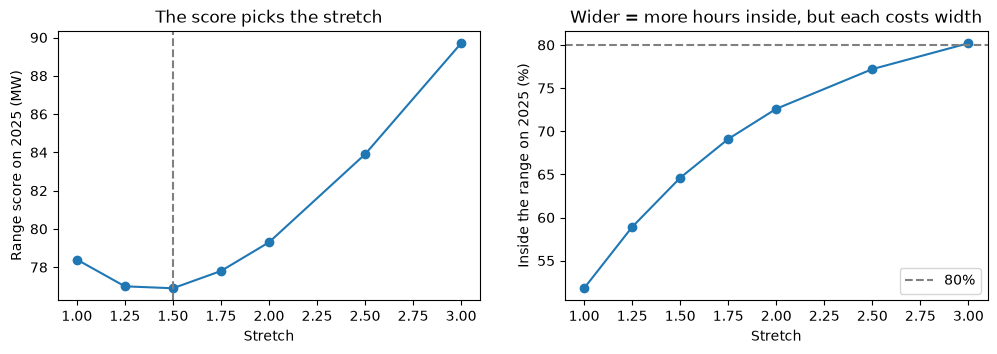

,method,inside_range_pct,avg_width_mw,expected_mae_mw,range_score
0,random forest spread,76.6,405,142.5,92.0
1,quantile forest,82.4,464,144.1,92.1
2,quantile boosting,54.9,221,109.8,78.5
3,linear quantile regression,56.2,449,235.0,170.5
4,"quantile boosting, widened",67.6,331,109.8,77.7


In [17]:
started = time.time()
train_years = X_train.index.tz_convert("America/New_York").year
early = train_years < TEST_YEAR - 1                   # 2023 and 2024
valid = train_years == TEST_YEAR - 1                  # 2025: the validation year
check = {}
for quantile in QUANTILES:
    check[quantile] = quantile_booster(quantile).fit(X_train.loc[early, PLUS], y_train[early])
v_low = check[0.1].predict(X_train.loc[valid, PLUS])
v_mid = check[0.5].predict(X_train.loc[valid, PLUS])
v_high = check[0.9].predict(X_train.loc[valid, PLUS])
seen = judge("years it trained on", check[0.1].predict(X_train.loc[early, PLUS]),
             check[0.5].predict(X_train.loc[early, PLUS]), check[0.9].predict(X_train.loc[early, PLUS]),
             actual=y_train[early])
print("Inside the range on the years it trained on:", seen["inside_range_pct"], "%")

rows = []
for stretch in [1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]:
    row = judge("stretch " + str(stretch), v_mid - stretch * (v_mid - v_low), v_mid, v_mid + stretch * (v_high - v_mid),
                actual=y_train[valid])
    row["stretch"] = stretch
    rows.append(row)
widen = pd.DataFrame(rows)
best_stretch = widen.loc[widen["range_score"].idxmin(), "stretch"]
print("Inside the range on the validation year, no stretch:", widen["inside_range_pct"].iloc[0], "%")
print("Best stretch on the validation year:", best_stretch, "| done in", round(time.time() - started), "seconds")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(widen["stretch"], widen["range_score"], marker="o")
ax[0].axvline(best_stretch, color="gray", linestyle="--")
ax[0].set_xlabel("Stretch")
ax[0].set_ylabel("Range score on " + str(TEST_YEAR - 1) + " (MW)")
ax[0].set_title("The score picks the stretch")
ax[1].plot(widen["stretch"], widen["inside_range_pct"], marker="o")
ax[1].axhline(80, color="gray", linestyle="--", label="80%")
ax[1].set_xlabel("Stretch")
ax[1].set_ylabel("Inside the range on " + str(TEST_YEAR - 1) + " (%)")
ax[1].set_title("Wider = more hours inside, but each costs width")
ax[1].legend()
plt.show()

# Apply the stretch chosen on the validation year to the test-year range from 4c (models trained on all training years)
mid = ranges["quantile boosting"]["expected"]
ranges["quantile boosting, widened"] = pd.DataFrame({"low": mid - best_stretch * (mid - ranges["quantile boosting"]["low"]),
                                                     "expected": mid,
                                                     "high": mid + best_stretch * (ranges["quantile boosting"]["high"] - mid)})
results.append(judge("quantile boosting, widened", ranges["quantile boosting, widened"]["low"], mid,
                     ranges["quantile boosting, widened"]["high"]))
pd.DataFrame(results)

**Read it:** the best stretch is modest, and the widened range still holds well under 80%. Stretching all the way to
80% costs more width than the misses it saves, because the misses come in **bunches** (a heat wave the model
underestimates for days, a holiday week) that a uniform stretch can't target: to catch them, it widens every calm hour
too. The score is the judge. "Honest" means the right range for **each** hour; reaching 80% on average by stretching
everything is not the same thing.

### 4f. Head to head
The point forecast from Part 1 is in the table too: a "range" with low = expected = high, so its score is just its MAE.

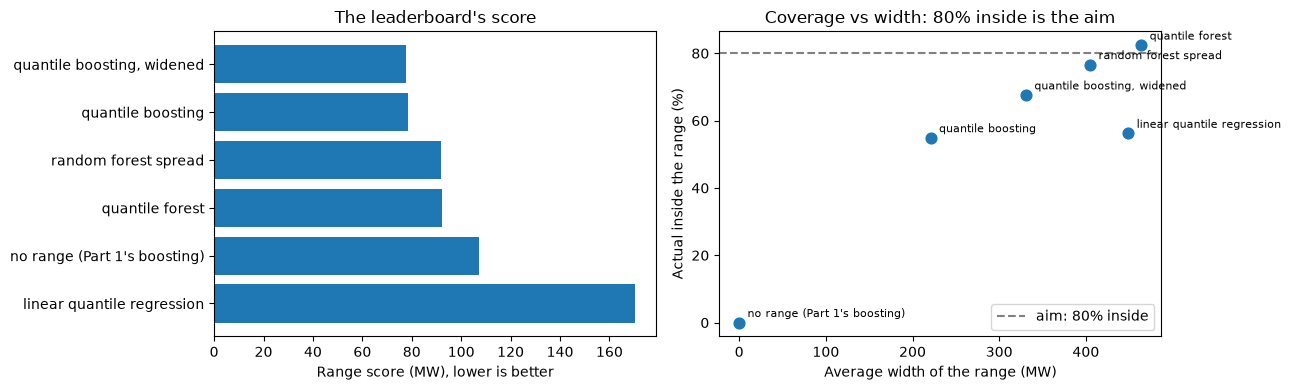

,method,inside_range_pct,avg_width_mw,expected_mae_mw,range_score
0,"quantile boosting, widened",67.6,331,109.8,77.7
1,quantile boosting,54.9,221,109.8,78.5
2,random forest spread,76.6,405,142.5,92.0
3,quantile forest,82.4,464,144.1,92.1
4,no range (Part 1's boosting),0.0,0,107.3,107.3
5,linear quantile regression,56.2,449,235.0,170.5


In [18]:
results.append(judge("no range (Part 1's boosting)", pred_boost, pred_boost, pred_boost))
board = pd.DataFrame(results).drop_duplicates("method", keep="last").sort_values("range_score").reset_index(drop=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(board["method"], board["range_score"])
ax[0].invert_yaxis()
ax[0].set_xlabel("Range score (MW), lower is better")
ax[0].set_title("The leaderboard's score")
ax[1].scatter(board["avg_width_mw"], board["inside_range_pct"], s=60)
for i in range(len(board)):
    ax[1].annotate(board["method"].iloc[i], (board["avg_width_mw"].iloc[i], board["inside_range_pct"].iloc[i]),
                   textcoords="offset points", xytext=(6, 4), fontsize=8)
ax[1].axhline(80, color="gray", linestyle="--", label="aim: 80% inside")
ax[1].set_xlabel("Average width of the range (MW)")
ax[1].set_ylabel("Actual inside the range (%)")
ax[1].set_title("Coverage vs width: 80% inside is the aim")
ax[1].legend()
plt.tight_layout()
plt.show()
board

**All four on the hottest week of the test year.** The band should be wider when the forecast is harder.

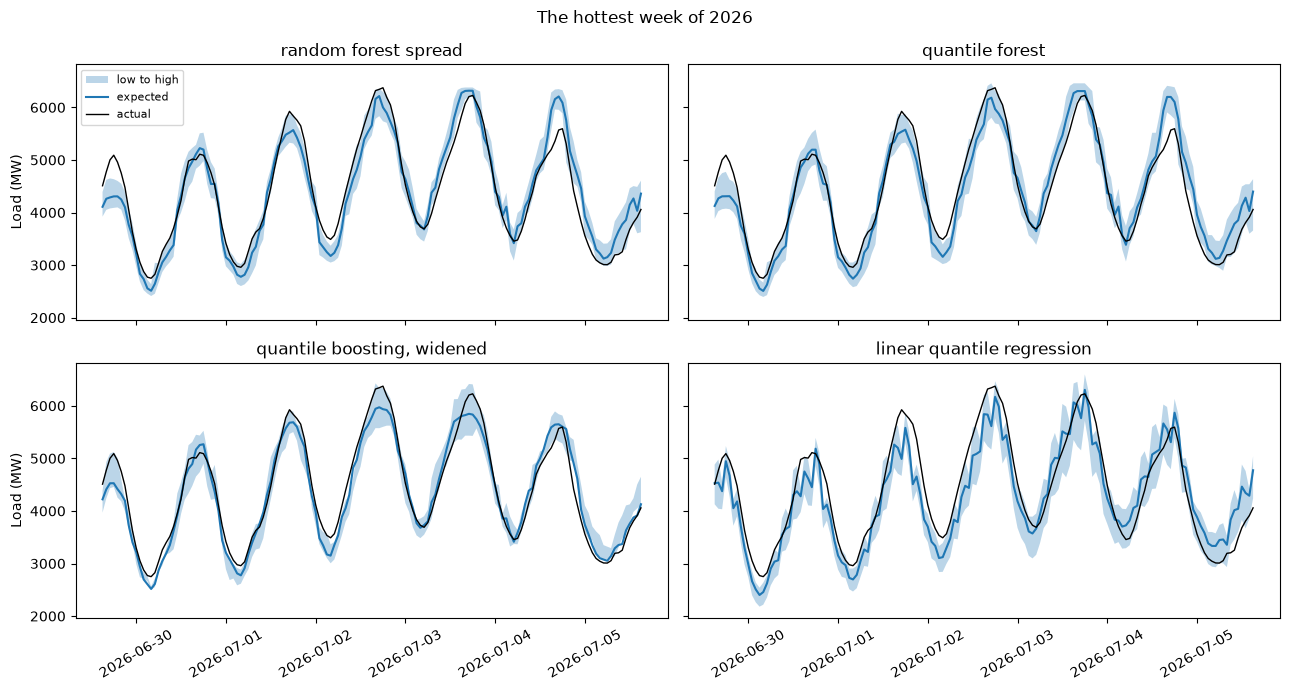

In [19]:
hottest = X_test["temp_f"].idxmax()
week_hours = X_test.loc[hottest - pd.Timedelta(days=3):hottest + pd.Timedelta(days=3)].index
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True)
methods = ["random forest spread", "quantile forest", "quantile boosting, widened", "linear quantile regression"]
for i in range(4):
    axis = axes.flat[i]
    week = ranges[methods[i]].loc[week_hours]
    hours_local = week.index.tz_convert("America/New_York")
    axis.fill_between(hours_local, week["low"], week["high"], alpha=0.3, label="low to high")
    axis.plot(hours_local, week["expected"], label="expected")
    axis.plot(hours_local, y_test.loc[week_hours].values, color="black", linewidth=1, label="actual")
    axis.set_title(methods[i])
    axis.tick_params(axis="x", rotation=30)
axes.flat[0].legend(fontsize=8)
axes.flat[0].set_ylabel("Load (MW)")
axes.flat[2].set_ylabel("Load (MW)")
plt.suptitle("The hottest week of " + str(TEST_YEAR))
plt.tight_layout()
plt.show()

### 4g. Is the best range honest at every hour of the day?
The winner's width and coverage by hour (Connecticut time).

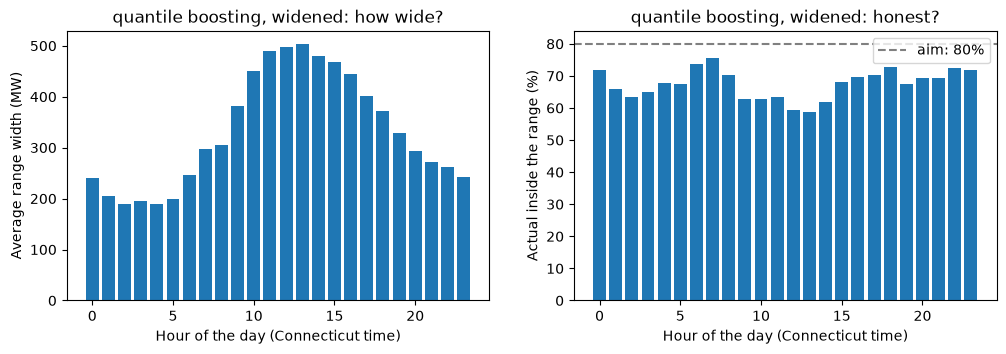

In [20]:
best = board[board["method"] != "no range (Part 1's boosting)"]["method"].iloc[0]
table = ranges[best].copy()
table["actual"] = y_test.values
table["width"] = table["high"] - table["low"]
table["inside"] = (table["actual"] >= table["low"]) & (table["actual"] <= table["high"])
by_hour = table.groupby(table.index.tz_convert("America/New_York").hour)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(by_hour["width"].mean().index, by_hour["width"].mean().values)
ax[0].set_xlabel("Hour of the day (Connecticut time)")
ax[0].set_ylabel("Average range width (MW)")
ax[0].set_title(best + ": how wide?")
ax[1].bar(by_hour["inside"].mean().index, 100 * by_hour["inside"].mean().values)
ax[1].axhline(80, color="gray", linestyle="--", label="aim: 80%")
ax[1].set_xlabel("Hour of the day (Connecticut time)")
ax[1].set_ylabel("Actual inside the range (%)")
ax[1].set_title(best + ": honest?")
ax[1].legend()
plt.show()

**Read it:** the winner is the model with the best **expected** value, widened on a validation year. A sharp center
matters more than a perfect 80%: every method's score starts from half its expected miss. A sensible range beats no
range at all, because a bit of width costs less than the misses it saves. And look at the hours: the range is
**widest around midday** (rooftop solar makes midday load hard to call: a cloud over Connecticut and the grid suddenly
needs more), and how often it holds the actual swings from about 60% to 75% by hour. One stretch for every hour leaves
points on the table. That's where Lab 6's **offsets by hour** come in.

**One honest warning:** every range here was built and tested with the weather that **actually happened**. In
production your model only gets the **forecast**, which is wrong too, so live misses are bigger and your live
**Inside range** will come in **below** what you see here. That's why Lab 6 lets you widen the range before you ship
it (`range_widen`), and why you check the leaderboard's **Inside range** column after a few days.

# Part 5 · Tomorrow's range (5 min)
The range for the next 24 hours, built the way `forecast-24h` would: the newest weather forecast and the live load from
**your** energy bucket. Production can only build Lab 5's 11 features today (no week of live load yet), so this forest
uses those 11. Type your project and bucket, run, and pick your energy Gmail in the pop-up. No energy project? Set
`USE_MY_BUCKET = False` for a demo on the last day of the test year.

In [21]:
PROJECT_ID = "YOUR-ENERGY-PROJECT-ID"
BUCKET_NAME = "YOUR-ENERGY-PROJECT-ID"
USE_MY_BUCKET = True

Type your PROJECT_ID and BUCKET_NAME above first. Demo mode for now.
DEMO: the last day of the test year


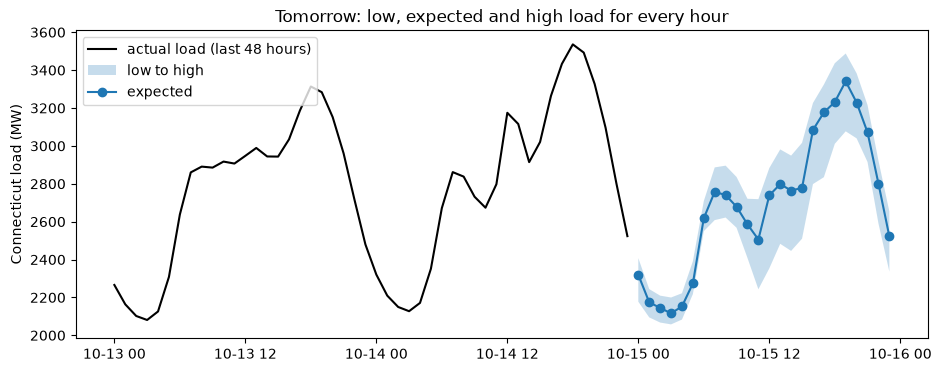

,low_mw,expected_mw,high_mw
hour (Connecticut time),,,
Thu 12 AM,2177.0,2320.0,2407.0
Thu 01 AM,2095.0,2174.0,2244.0
Thu 02 AM,2068.0,2145.0,2210.0
Thu 03 AM,2058.0,2116.0,2200.0
Thu 04 AM,2083.0,2153.0,2222.0
Thu 05 AM,2218.0,2274.0,2391.0
Thu 06 AM,2550.0,2618.0,2709.0
Thu 07 AM,2608.0,2757.0,2886.0
Thu 08 AM,2622.0,2740.0,2896.0


In [22]:
qrf_11 = RandomForestQuantileRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
qrf_11.fit(X_train[FEATURES], y_train)

if USE_MY_BUCKET and "YOUR-ENERGY-PROJECT-ID" in PROJECT_ID + BUCKET_NAME:
    print("Type your PROJECT_ID and BUCKET_NAME above first. Demo mode for now.")
    USE_MY_BUCKET = False

mine = None
isone = None
if USE_MY_BUCKET:
    from google.colab import auth
    from google.cloud import storage
    auth.authenticate_user()
    bucket = storage.Client(project=PROJECT_ID).bucket(BUCKET_NAME)

    def read_bucket_csv(key):
        blob = bucket.blob(key)
        if not blob.exists():
            return None
        return pd.read_csv(io.BytesIO(blob.download_as_bytes()))

    forecasts = read_bucket_csv("energy/datasets/bdl_weather_forecast_master.csv")
    forecasts["scraped_hour_utc"] = pd.to_datetime(forecasts["scraped_hour_utc"], utc=True)
    forecasts["target_hour_utc"] = pd.to_datetime(forecasts["target_hour_utc"], utc=True)
    forecasts = forecasts.sort_values(["target_hour_utc", "scraped_hour_utc"])
    weather = forecasts.drop_duplicates("target_hour_utc", keep="last").set_index("target_hour_utc")
    load_table = read_bucket_csv("energy/datasets/ct_load_5min_hourly_master.csv")
    load_table["hour_utc"] = pd.to_datetime(load_table["hour_utc"], utc=True)
    load = load_table.set_index("hour_utc")["load_mw_5min_avg"].sort_index()

    this_hour = pd.Timestamp.now(tz="UTC").floor("h")
    targets = pd.date_range(this_hour + pd.Timedelta(hours=1), periods=24, freq="h")
    X_next = make_features(targets, weather, load)
    X_next[WEATHER] = X_next[WEATHER].interpolate(limit_direction="both")      # the same gap filling as production
    X_next["load_yesterday_mw"] = X_next["load_yesterday_mw"].fillna(float(load.iloc[-1]))
    actual = load.tail(48)

    latest = read_bucket_csv("energy/forecasts/latest.csv")
    if latest is not None:
        latest["target_hour_utc"] = pd.to_datetime(latest["target_hour_utc"], utc=True)
        mine = latest.set_index("target_hour_utc")["predicted_load_mw"]
    isone_table = read_bucket_csv("energy/datasets/isone_ct_forecast_master.csv")
    if isone_table is not None:
        isone_table["target_hour_utc"] = pd.to_datetime(isone_table["target_hour_utc"], utc=True)
        isone_table = isone_table.sort_values(["target_hour_utc", "issued_at_utc"])
        isone = isone_table.drop_duplicates("target_hour_utc", keep="last").set_index("target_hour_utc")["isone_forecast_mw"]
    print("LIVE: the next 24 hours from your bucket")
else:
    targets = X_test.index[-24:]
    X_next = X_test.loc[targets, FEATURES]
    actual = y_test.loc[X_test.index[-72:-24]]
    print("DEMO: the last day of the test year")

q_next = qrf_11.predict(X_next[FEATURES], quantiles=QUANTILES)
tomorrow = pd.DataFrame({"low_mw": q_next[:, 0], "expected_mw": q_next[:, 1], "high_mw": q_next[:, 2]}, index=targets)

plt.figure(figsize=(11, 4))
plt.plot(actual.index.tz_convert("America/New_York"), actual.values, color="black", label="actual load (last 48 hours)")
hours_local = tomorrow.index.tz_convert("America/New_York")
plt.fill_between(hours_local, tomorrow["low_mw"], tomorrow["high_mw"], alpha=0.25, label="low to high")
plt.plot(hours_local, tomorrow["expected_mw"], marker="o", label="expected")
if mine is not None:
    mine_next = mine.reindex(tomorrow.index)
    plt.plot(hours_local, mine_next.values, linestyle=":", label="your Lab 5 model (deployed)")
if isone is not None:
    isone_next = isone.reindex(tomorrow.index)
    if isone_next.notna().any():
        plt.plot(hours_local, isone_next.values, linestyle="--", label="ISO New England's forecast")
plt.ylabel("Connecticut load (MW)")
plt.title("Tomorrow: low, expected and high load for every hour")
plt.legend()
plt.show()

table = tomorrow.round(0)
table.index = hours_local.strftime("%a %I %p")
table.index.name = "hour (Connecticut time)"
table

# Part 6 · Wrap up (4 min)

## Five short answers (1 or 2 sentences each)
1. In Part 1c, which group of lags saved the most MW? Why can't production use the load from 1 hour ago?
2. Did tsfresh's features help on top of Part 1's lags? What does that tell you about where the signal was?
3. Did the ensemble beat gradient boosting alone? Why or why not?
4. Which range method had the lowest range score? Why does a model's range get too narrow on a year it never saw?
5. Why will your live **Inside range** be lower than the one you measured here?

*Your answers:*

---

## Ideas for the final project
- **Ship the better features:** copy `make_features_plus` into `make_features` in your fork's
  `cloud_function/forecast-24h/main.py` and into Lab 5 Part 3, push, wait for a green **Deploy forecast-24h**, then ship
  the model trained on them. The week-old lag needs a week of load in your bucket first (Part 1).
- **Ship the range:** Lab 6 walks you through it: train low and high models and let `forecast-24h` write `low_mw` and
  `high_mw` next to `predicted_load_mw`. For a quantile forest, add `quantile-forest==1.4.2` to
  `cloud_function/forecast-24h/requirements.txt`.
- **The direct strategy:** 24 models, one per hour ahead, each allowed the freshest lag its lead permits.
- **tsfresh in production:** `tsfresh==0.21.2` in `requirements.txt`, at least 9 days of load in the bucket, the same
  window rule as Part 2.
- **More weather:** more stations than Bradley, more variables. Every new input must also exist in production, every hour.
- **One great model, or a tuned ensemble:** choose the weights on a validation period, never the test year.